# Personalized Workout Recommendation System — Analysis Notebook

**Subject:** Recommendation Systems · **Technique:** Content-Based Filtering + Cosine Similarity

This notebook walks through the complete pipeline used by the Streamlit app:

`User Input → User Profile → Feature Extraction → Content-Based Filtering → Feature Vectors → Cosine Similarity → Ranking → Top-N → Personalized Workout`

It imports the **same modules** as `app.py` (`model/`, `utils/`, `evaluation/`), so the numbers here are exactly what the web app produces.

> ⚠️ Educational project. Recommendations are general informational suggestions, not medical advice.

## 1. Import libraries

In [1]:
import sys, json, warnings
from pathlib import Path

# Make the project root importable whether the notebook runs from notebooks/ or the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model.config import FEATURE_WEIGHTS, BLOCK_LABELS, DISCLAIMER
from model.user_profile import UserProfile, build_profile
from model.recommender import WorkoutRecommender, FeatureEncoder, BLOCK_ORDER, FILTER_STAGES
from utils.preprocessing import load_raw_dataset, clean_exercise_data
from utils.workout_generator import recommend_and_generate, generate_workout
from utils.explanations import explain_exercise, score_breakdown
from evaluation.evaluate import (precision_at_k, recall_at_k, cosine_similarity_manual,
                                 evaluate_sample_users, evaluate_grid, cosine_verification)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Project root:", ROOT)

Project root: /home/claude/P


## 2. Load the dataset

In [2]:
DATA = ROOT / "data" / "exercises.csv"
raw = load_raw_dataset(DATA)
print(f"Loaded {len(raw)} rows × {raw.shape[1]} columns from {DATA.relative_to(ROOT)}")
raw.head()

Loaded 298 rows × 17 columns from data/exercises.csv


,exercise_id,exercise_name,muscle_group,equipment,difficulty,goal,exercise_type,duration_minutes,calories_burned,sets,reps,rest_seconds,instructions,safety_notes,mechanics,movement_pattern,tags
0,EX001,Push-Up,Chest,No Equipment,Beginner,General Fitness|Muscle Gain|Endurance,Strength,3.5,15,2,10-12,60,"1) Setup: Find a clear, non-slip floor space. ...",Keep wrists stacked over elbows and avoid flar...,Compound,h_push,push-up push press horizontal pectorals tricep...
1,EX002,Knee Push-Up,Chest,No Equipment,Beginner,General Fitness|Endurance,Strength,3.5,15,2,10-12,60,"1) Setup: Find a clear, non-slip floor space. ...",Keep wrists stacked over elbows and avoid flar...,Compound,h_push,knee push-up push press horizontal pectorals t...
2,EX003,Incline Push-Up,Chest,Bench,Beginner,General Fitness|Endurance,Strength,3.5,15,2,10-12,60,"1) Setup: Use a stable, flat bench or box on a...",Keep wrists stacked over elbows and avoid flar...,Compound,h_push,incline push-up push press horizontal pectoral...
3,EX004,Decline Push-Up,Chest,Bench,Intermediate,Muscle Gain|General Fitness,Strength,7.9,48,4,8-10,90,"1) Setup: Use a stable, flat bench or box on a...",Keep wrists stacked over elbows and avoid flar...,Compound,h_push,decline push-up push press horizontal pectoral...
4,EX005,Wide-Grip Push-Up,Chest,No Equipment,Beginner,General Fitness|Muscle Gain,Strength,3.5,15,2,10-12,60,"1) Setup: Find a clear, non-slip floor space. ...",Keep wrists stacked over elbows and avoid flar...,Compound,h_push,wide-grip push-up push press horizontal pector...


## 3. Dataset overview

In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 298 entries, 0 to 297
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   exercise_id       298 non-null    str    
 1   exercise_name     298 non-null    str    
 2   muscle_group      298 non-null    str    
 3   equipment         298 non-null    str    
 4   difficulty        298 non-null    str    
 5   goal              298 non-null    str    
 6   exercise_type     298 non-null    str    
 7   duration_minutes  298 non-null    float64
 8   calories_burned   298 non-null    int64  
 9   sets              298 non-null    int64  
 10  reps              298 non-null    str    
 11  rest_seconds      298 non-null    int64  
 12  instructions      298 non-null    str    
 13  safety_notes      298 non-null    str    
 14  mechanics         298 non-null    str    
 15  movement_pattern  298 non-null    str    
 16  tags              298 non-null    str    
dtypes: float

In [4]:
overview = pd.DataFrame({
    "Unique values": raw.nunique(),
    "Example": raw.iloc[0],
})
overview

,Unique values,Example
exercise_id,298,EX001
exercise_name,298,Push-Up
muscle_group,10,Chest
equipment,11,No Equipment
difficulty,3,Beginner
goal,23,General Fitness|Muscle Gain|Endurance
exercise_type,5,Strength
duration_minutes,19,3.5
calories_burned,27,15
sets,6,2


In [5]:
raw[["duration_minutes", "calories_burned", "sets", "rest_seconds"]].describe().round(1)

,duration_minutes,calories_burned,sets,rest_seconds
count,298.0,298.0,298.0,298.0
mean,5.7,36.8,3.1,63.8
std,2.7,26.7,1.2,39.0
min,2.2,6.0,1.0,0.0
25%,3.5,15.0,2.0,45.0
50%,5.2,29.5,3.0,60.0
75%,7.9,54.0,4.0,90.0
max,16.0,137.0,8.0,150.0


Calories are **approximate educational values** (MET-based estimates for a ~70 kg person), not medically accurate measurements.

## 4. Data cleaning

`utils.preprocessing.clean_exercise_data` performs every step below. To *demonstrate* it,
we create a deliberately corrupted copy of the data (the real file is left untouched):
a duplicate row, a missing muscle group, an invalid negative duration, a text value in a numeric
column, inconsistent capitalisation and a missing instruction.

In [6]:
dirty = raw.copy()
dirty = pd.concat([dirty, dirty.iloc[[0]]], ignore_index=True)        # duplicate exercise
dirty.loc[1, "muscle_group"] = np.nan                                  # missing category
dirty.loc[2, "duration_minutes"] = -5                                  # invalid numeric
dirty["calories_burned"] = dirty["calories_burned"].astype(object)
dirty.loc[3, "calories_burned"] = "lots"                               # non-numeric value
dirty.loc[4, "difficulty"] = "  beginner "                             # inconsistent text
dirty.loc[5, "instructions"] = np.nan                                  # missing text

cleaned_demo, report = clean_exercise_data(dirty)
pd.Series(report.as_dict(), name="Cleaning report").to_frame()

,Cleaning report
Rows loaded,299
Rows after cleaning,297
Missing values (before cleaning),2
Invalid numeric values repaired,2
Rows dropped (unknown/missing category),1
Duplicate exercises removed,1
Missing text fields filled,1


## 5. Missing-value analysis

In [7]:
missing = pd.DataFrame({"Missing (corrupted copy)": dirty.isna().sum(),
                        "Missing (after cleaning)": cleaned_demo[dirty.columns].isna().sum()})
missing[missing.sum(axis=1) > 0]

,Missing (corrupted copy),Missing (after cleaning)
muscle_group,1,0
instructions,1,0


In [8]:
# The real dataset, cleaned exactly as the app does
df, real_report = clean_exercise_data(raw)
print(real_report.as_dict())
print("Missing values in cleaned data:", int(df[raw.columns].isna().sum().sum()))

{'Rows loaded': 298, 'Rows after cleaning': 298, 'Missing values (before cleaning)': 0, 'Invalid numeric values repaired': 0, 'Rows dropped (unknown/missing category)': 0, 'Duplicate exercises removed': 0, 'Missing text fields filled': 0}
Missing values in cleaned data: 0


## 6. Exploratory data analysis

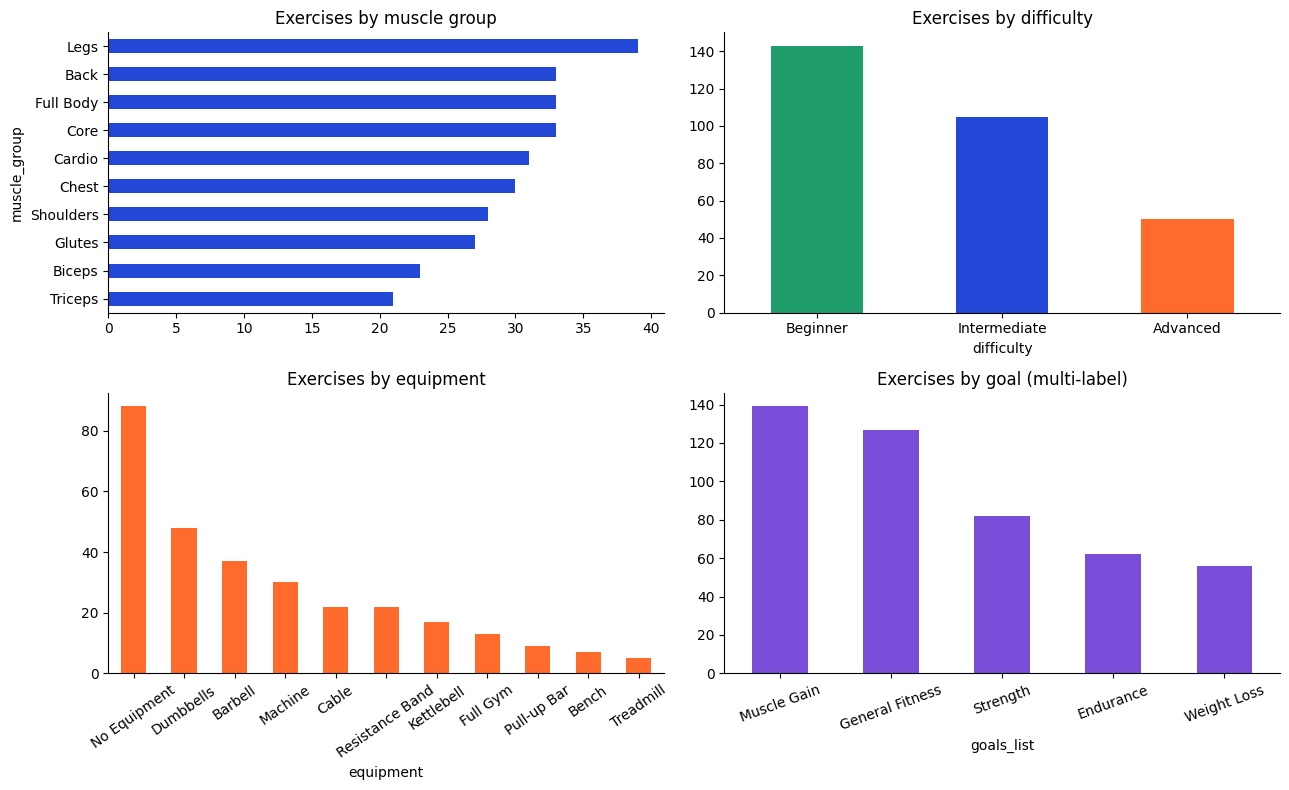

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
df["muscle_group"].value_counts().sort_values().plot.barh(ax=axes[0, 0], color="#2347D6")
axes[0, 0].set_title("Exercises by muscle group")
df["difficulty"].value_counts().reindex(["Beginner", "Intermediate", "Advanced"]).plot.bar(
    ax=axes[0, 1], color=["#1F9D6B", "#2347D6", "#FF6B2C"], rot=0)
axes[0, 1].set_title("Exercises by difficulty")
df["equipment"].value_counts().plot.bar(ax=axes[1, 0], color="#FF6B2C", rot=35)
axes[1, 0].set_title("Exercises by equipment")
df["goals_list"].explode().value_counts().plot.bar(ax=axes[1, 1], color="#7A4DD8", rot=20)
axes[1, 1].set_title("Exercises by goal (multi-label)")
plt.tight_layout(); plt.show()

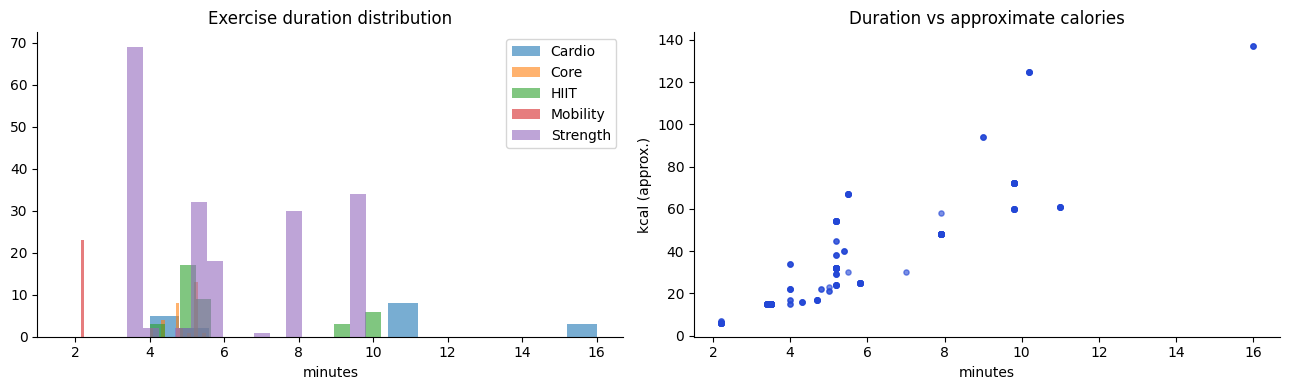

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for t, g in df.groupby("exercise_type"):
    axes[0].hist(g["duration_minutes"], bins=15, alpha=.6, label=t)
axes[0].set_title("Exercise duration distribution"); axes[0].set_xlabel("minutes"); axes[0].legend()
axes[1].scatter(df["duration_minutes"], df["calories_burned"], s=14, alpha=.6, c="#2347D6")
axes[1].set_title("Duration vs approximate calories"); axes[1].set_xlabel("minutes"); axes[1].set_ylabel("kcal (approx.)")
plt.tight_layout(); plt.show()

In [11]:
pd.crosstab(df["muscle_group"], df["difficulty"])[["Beginner", "Intermediate", "Advanced"]]

difficulty,Beginner,Intermediate,Advanced
muscle_group,,,
Back,21,8,4
Biceps,13,9,1
Cardio,13,11,7
Chest,11,15,4
Core,15,13,5
Full Body,11,11,11
Glutes,13,11,3
Legs,22,10,7
Shoulders,14,9,5


## 7. Feature engineering

Each exercise is represented by **8 feature blocks**:

| Block | Encoding | Weight |
|---|---|---|
| Goal | multi-hot (primary goal 1.0, secondary 0.6) | 3.0 |
| Target muscle | one-hot over muscle groups | 3.0 |
| Equipment | 8 equipment characteristics (bodyweight, free weight, machine, elastic, …) | 2.5 |
| Fitness level | one-hot difficulty | 2.5 |
| Exercise type | one-hot type | 1.5 |
| Duration | soft Gaussian bins over log(minutes) | 1.0 |
| Difficulty proximity | one-hot difficulty (user side: graded affinity) | 1.0 |
| Keyword profile | **TF-IDF** of the exercise's keyword tags | 1.0 |

Each block is L2-normalised and multiplied by √weight, then all blocks are concatenated.

In [12]:
pd.DataFrame({"Feature block": [BLOCK_LABELS[b] for b in BLOCK_ORDER],
              "Weight": [FEATURE_WEIGHTS[b] for b in BLOCK_ORDER]})

,Feature block,Weight
0,Goal,3.0
1,Target muscle,3.0
2,Equipment,2.5
3,Fitness level,2.5
4,Exercise type,1.5
5,Duration,1.0
6,Difficulty proximity,1.0
7,Keyword profile (TF-IDF),1.0


## 8. Encoding (fitting the feature encoder)

In [13]:
rec = WorkoutRecommender(df)          # fits FeatureEncoder on the cleaned dataset
enc = rec.encoder
print("Exercise matrix shape:", rec.X.shape)
pd.DataFrame({"Block": [BLOCK_LABELS[b] for b in BLOCK_ORDER],
              "Dimensions": [len(enc.vocab[b]) for b in BLOCK_ORDER]})

Exercise matrix shape: (298, 400)


,Block,Dimensions
0,Goal,5
1,Target muscle,10
2,Equipment,8
3,Fitness level,3
4,Exercise type,5
5,Duration,6
6,Difficulty proximity,3
7,Keyword profile (TF-IDF),360


In [14]:
# TF-IDF vocabulary sample and one exercise's keyword document
print("TF-IDF terms:", len(enc.vocab["text"]), "→", enc.vocab["text"][:20])
print("Bench Press tags:", df.loc[df.exercise_name == "Bench Press", "tags"].iloc[0])

TF-IDF terms: 360 → ['ab', 'abdominals', 'abduction', 'activation', 'aerobic', 'and', 'angel', 'ankle', 'anti-rotation', 'archer', 'arm', 'arms', 'arnold', 'assault', 'assisted', 'b-stance', 'back', 'back-width', 'balance', 'ball']
Bench Press tags: bench press push press horizontal pectorals triceps compound free-weight barbell heavy resistance strength chest moderate


## 9. User profile (demo user)

In [15]:
demo_input = {"age": 21, "height_cm": 175, "weight_kg": 70, "fitness_level": "Intermediate",
              "goal": "Muscle Gain", "target_muscle": "Chest", "equipment": "Full Gym",
              "duration": 60, "days_per_week": 5, "exercise_type": "Strength"}
profile, errors = build_profile(demo_input)
print("Validation errors:", errors)
print(profile)
print(f"BMI = {profile.bmi} ({profile.bmi_category}) — informational only")

Validation errors: []
UserProfile(age=21, height_cm=175.0, weight_kg=70.0, fitness_level='Intermediate', goal='Muscle Gain', target_muscle='Chest', equipment='Full Gym', duration=60, days_per_week=5, exercise_type='Strength')
BMI = 22.9 (Normal range) — informational only


In [16]:
# Input validation example
print(build_profile({**demo_input, "age": 7, "goal": None})[1])

['Age must be between 14 and 80.', 'Please select your primary goal.']


## 10. User feature vector

In [17]:
user_vec = enc.encode_user(profile).ravel()
vec_df = pd.DataFrame({"feature": enc.feature_names(), "value": user_vec})
nonzero = vec_df[vec_df.value.abs() > 1e-9]
print(f"{len(nonzero)} of {len(user_vec)} dimensions are non-zero; ||U|| = {np.linalg.norm(user_vec):.4f}")
nonzero.head(30).round(4)

34 of 400 dimensions are non-zero; ||U|| = 3.9370


,feature,value
1,goal:Muscle Gain,1.5492
2,goal:Strength,0.7746
5,muscle:Chest,1.5476
7,muscle:Shoulders,0.4643
9,muscle:Triceps,0.5417
13,muscle:Full Body,0.3095
15,equipment:bodyweight,0.1811
16,equipment:free_weight,0.7243
17,equipment:external_load,0.9054
18,equipment:guided,0.7243


## 11. Cosine similarity

$$\cos(A,B)=\frac{A\cdot B}{\lVert A\rVert\,\lVert B\rVert}$$

We compute it manually for one exercise and compare with scikit-learn (used by the engine).

In [18]:
from sklearn.metrics.pairwise import cosine_similarity
row = df.index[df.exercise_name == "Bench Press"][0]
A, B = user_vec, rec.X[row]
manual = A @ B / (np.linalg.norm(A) * np.linalg.norm(B))
sk = cosine_similarity(A.reshape(1, -1), B.reshape(1, -1))[0, 0]
print(f"A·B = {A @ B:.4f}, ||A|| = {np.linalg.norm(A):.4f}, ||B|| = {np.linalg.norm(B):.4f}")
print(f"manual cosine = {manual:.6f} | scikit-learn = {sk:.6f} | equal: {np.isclose(manual, sk)}")

A·B = 13.7683, ||A|| = 3.9370, ||B|| = 3.9370
manual cosine = 0.888276 | scikit-learn = 0.888276 | equal: True


In [19]:
cosine_verification(rec).round(4)

,Exercise,A·B,||A||,||B||,Manual cosine,scikit-learn cosine,Equal
0,Smith Machine Incline Press,13.9533,3.937,3.937,0.9002,0.9002,True
1,Bench Press,13.7683,3.937,3.937,0.8883,0.8883,True
2,Chest Dips,13.6640,3.937,3.937,0.8815,0.8815,True
3,Incline Barbell Bench Press,13.6364,3.937,3.937,0.8798,0.8798,True
4,Decline Barbell Bench Press,13.3858,3.937,3.937,0.8636,0.8636,True


## 12. Content-based filtering + ranking

In [20]:
result = rec.recommend(profile, top_n=10)
print("Filter stage:", result.filter_stage, "| eligible exercises:", result.n_eligible, "of", len(df))
print("Relaxation cascade:", FILTER_STAGES)
result.ranked[["rank", "exercise_name", "match_percent", "muscle_group", "equipment",
               "difficulty", "exercise_type"]].head(15)

Filter stage: Strict match | eligible exercises: 25 of 298
Relaxation cascade: ['Strict match', 'Relaxed difficulty', 'Relaxed secondary constraints', 'Broad (equipment only)']


,rank,exercise_name,match_percent,muscle_group,equipment,difficulty,exercise_type
0,1,Smith Machine Incline Press,90.0,Chest,Machine,Intermediate,Strength
1,2,Bench Press,88.8,Chest,Barbell,Intermediate,Strength
2,3,Chest Dips,88.2,Chest,Full Gym,Intermediate,Strength
3,4,Incline Barbell Bench Press,88.0,Chest,Barbell,Intermediate,Strength
4,5,Decline Barbell Bench Press,86.4,Chest,Barbell,Intermediate,Strength
5,6,Cable Fly,86.0,Chest,Cable,Intermediate,Strength
6,7,Dumbbell Squeeze Press,85.9,Chest,Dumbbells,Intermediate,Strength
7,8,Low-to-High Cable Fly,85.7,Chest,Cable,Intermediate,Strength
8,9,High-to-Low Cable Fly,85.7,Chest,Cable,Intermediate,Strength
9,10,Incline Dumbbell Press,85.5,Chest,Dumbbells,Intermediate,Strength


In [21]:
# Every score decomposes exactly into per-feature contributions
top = result.top_n
contrib = top[[f"contrib_{b}" for b in BLOCK_ORDER]].sum(axis=1)
print("max |sum(contributions) - cosine| =", float(np.abs(contrib - top["similarity"]).max()))
score_breakdown(top.iloc[0])

max |sum(contributions) - cosine| = 3.3306690738754696e-16


,Feature,Block similarity,Contribution (%)
0,Goal,0.997054,19.3
1,Target muscle,0.893534,17.3
2,Equipment,0.859533,13.9
3,Fitness level,1.000000,16.1
4,Exercise type,0.970143,9.4
5,Duration,0.959401,6.2
6,Difficulty proximity,0.856706,5.5
7,Keyword profile (TF-IDF),0.361340,2.3


## 13. Top-N recommendations with explanations

In [22]:
for _, r in top.head(5).iterrows():
    print(f"#{r['rank']} {r['exercise_name']} — {r['match_percent']:.1f}% match")
    for reason in explain_exercise(r, profile):
        print("    ", reason)

#1 Smith Machine Incline Press — 90.0% match
     ✓ Matches your Muscle Gain goal (its primary purpose)
     ✓ Targets your selected Chest muscle group
     ✓ Suitable for Intermediate level
     ✓ Uses machine, available with your Full Gym setup
     ✓ Matches your preferred Strength training
     ✓ Fits your 60-minute session (about 7.9 min of ~9 min per exercise)
     ✓ Movement description closely matches your preferences (TF-IDF keyword similarity)
#2 Bench Press — 88.8% match
     ✓ Matches your Muscle Gain goal (its primary purpose)
     ✓ Targets your selected Chest muscle group
     ✓ Suitable for Intermediate level
     ✓ Uses barbell, available with your Full Gym setup
     ✓ Matches your preferred Strength training
     ✓ Fits your 60-minute session (about 7.9 min of ~9 min per exercise)
     ✓ Movement description closely matches your preferences (TF-IDF keyword similarity)
#3 Chest Dips — 88.2% match
     ✓ Matches your Muscle Gain goal (its primary purpose)
     ✓ Target

## 14. Workout generation

In [23]:
result, workout = recommend_and_generate(rec, profile, top_n=5)
wdf = workout.to_frame()[["order", "exercise_name", "sets", "reps", "rest_seconds",
                          "est_minutes", "calories", "match_percent"]]
print(f"Warm-up {workout.warmup_minutes} min + exercises {workout.exercise_minutes} min + "
      f"cool-down {workout.cooldown_minutes} min = {workout.total_minutes} min "
      f"(requested {profile.duration}); ≈{workout.total_calories(profile.weight_kg)} kcal (approx.)")
wdf

Warm-up 6 min + exercises 44.1 min + cool-down 4 min = 54.1 min (requested 60); ≈309 kcal (approx.)


,order,exercise_name,sets,reps,rest_seconds,est_minutes,calories,match_percent
0,1,Smith Machine Incline Press,5,8-10,90,10.0,60.8,90.0
1,2,Bench Press,4,8-10,90,7.9,48.0,88.8
2,3,Chest Dips,4,8-10,90,7.9,48.0,88.2
3,4,Incline Barbell Bench Press,4,8-10,90,7.9,48.0,88.0
4,5,Cable Fly,3,10-12,60,5.2,32.0,86.0
5,6,Dumbbell Pullover,3,10-12,60,5.2,32.0,83.6


In [24]:
# "Generate another workout": same constraints, different exercises where possible
alt = generate_workout(result, rec, variation=1, exclude_ids=workout.exercise_ids)
print("Original :", [i.exercise_name for i in workout.items])
print("Alternate:", [i.exercise_name for i in alt.items])
print("Shared exercises:", len(set(workout.exercise_ids) & set(alt.exercise_ids)))

Original : ['Smith Machine Incline Press', 'Bench Press', 'Chest Dips', 'Incline Barbell Bench Press', 'Cable Fly', 'Dumbbell Pullover']
Alternate: ['Chest Dips', 'Decline Barbell Bench Press', 'Incline Dumbbell Press', 'Kettlebell Floor Press', 'Low-to-High Cable Fly', 'Dumbbell Fly']
Shared exercises: 1


In [25]:
# All five sample users from data/sample_users.json
for d in json.loads((ROOT / "data" / "sample_users.json").read_text()):
    label = d.pop("label"); p = UserProfile.from_dict(d)
    r, w = recommend_and_generate(rec, p, top_n=5)
    print(f"{label}\n   stage={r.filter_stage}, eligible={r.n_eligible}, "
          f"{len(w.items)} exercises, {w.total_minutes} / {p.duration} min")
    print("   ", ", ".join(i.exercise_name for i in w.items))

1. Beginner + Weight Loss + No Equipment
   stage=Strict match, eligible=11, 4 exercises, 30.0 / 30 min
    Squat Thrust, Half Burpee, High Knees, Running


2. Intermediate + Muscle Gain + Full Gym (demo)
   stage=Strict match, eligible=25, 6 exercises, 54.1 / 60 min
    Smith Machine Incline Press, Bench Press, Chest Dips, Incline Barbell Bench Press, Cable Fly, Dumbbell Pullover


3. Advanced + Strength + Full Gym
   stage=Relaxed difficulty, eligible=32, 8 exercises, 85.6 / 90 min
    Barbell Front Squat, Pause Squat, Barbell Lunge, Barbell Romanian Deadlift, Bulgarian Split Squat, Dumbbell Romanian Deadlift, Nordic Hamstring Curl, Seated Calf Raise


4. Beginner + General Fitness + Home Gym
   stage=Strict match, eligible=13, 5 exercises, 36.6 / 45 min
    Resistance Band Woodchop, Crunch, Plank, Dumbbell Side Bend, Cobra Stretch


5. Intermediate + Endurance + Minimal Equipment (bands)
   stage=Strict match, eligible=26, 5 exercises, 40.5 / 45 min
    Jump Squat, Mountain Climbers, Burpee, Bear Crawl, Resistance Band Jumping Jacks


## 15. Evaluation — DEMONSTRATION / TEST ONLY

Real Precision@K / Recall@K need relevance labels from real users or trainers, which this
project does not have. `evaluation/evaluate.py` therefore builds a **clearly labelled synthetic
relevance set** from transparent rules. These numbers show *how* the metrics work; they are
**not** real-world accuracy and are optimistic by construction.

In [26]:
# Tiny worked example of the metric definitions
recommended = ["A", "B", "C", "D", "E"]; relevant = {"A", "C", "F", "G"}
print("Precision@5 =", precision_at_k(recommended, relevant, 5), "| Recall@5 =", recall_at_k(recommended, relevant, 5))

Precision@5 = 0.4 | Recall@5 = 0.5


In [27]:
users_eval = evaluate_sample_users(rec, k=5)
users_eval[["Profile", "n_relevant", "ours_precision", "ours_recall", "filter_precision", "random_precision"]].round(3)

,Profile,n_relevant,ours_precision,ours_recall,filter_precision,random_precision
0,1. Beginner + Weight Loss + No Equipment,10,1.0,0.500,0.92,0.08
1,2. Intermediate + Muscle Gain + Full Gym (demo),23,1.0,0.217,0.92,0.04
2,3. Advanced + Strength + Full Gym,11,1.0,0.455,0.68,0.00
3,4. Beginner + General Fitness + Home Gym,11,1.0,0.455,0.76,0.00
4,5. Intermediate + Endurance + Minimal Equipmen...,14,1.0,0.357,0.60,0.00


In [28]:
grid = evaluate_grid(rec, ks=(5, 10), max_profiles=300)
grid.round(3)

,K,System,Precision@K,Recall@K,nDCG@K,Profiles evaluated,Profiles skipped (no relevant items)
0,5,Content-based cosine (ours),0.725,0.541,0.837,262,38
1,5,Filter only (no ranking),0.521,0.394,0.562,262,38
2,5,Random (no personalisation),0.036,0.018,0.037,262,38
3,10,Content-based cosine (ours),0.584,0.759,0.818,262,38
4,10,Filter only (no ranking),0.447,0.569,0.539,262,38
5,10,Random (no personalisation),0.033,0.033,0.036,262,38


## 16. Visualizations

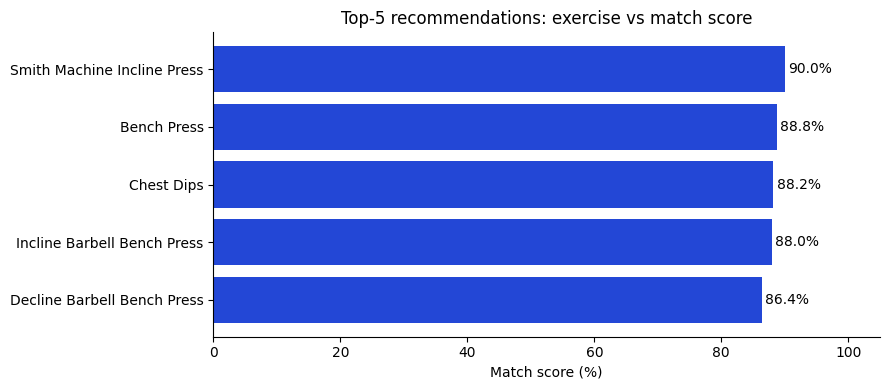

In [29]:
fig, ax = plt.subplots(figsize=(9, 4))
t = result.top_n.iloc[::-1]
ax.barh(t["exercise_name"], t["match_percent"], color="#2347D6")
for y, v in enumerate(t["match_percent"]):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center")
ax.set_xlim(0, 105); ax.set_xlabel("Match score (%)"); ax.set_title("Top-5 recommendations: exercise vs match score")
plt.tight_layout(); plt.show()

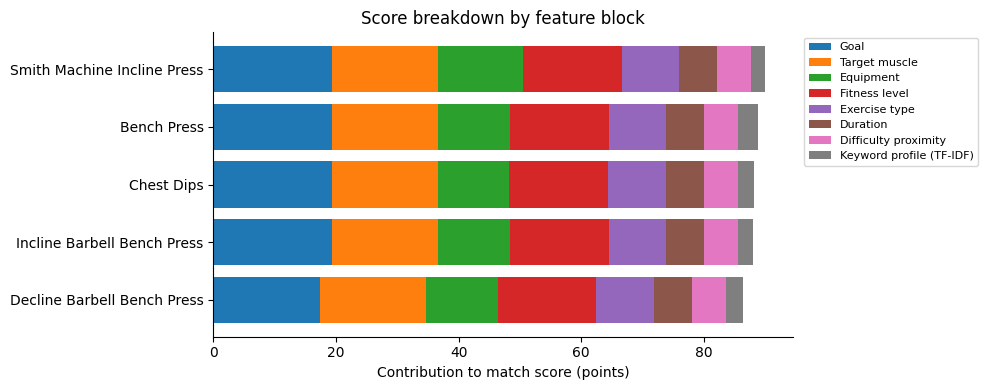

In [30]:
fig, ax = plt.subplots(figsize=(10, 4))
t = result.top_n.iloc[::-1]
left = np.zeros(len(t))
for b in BLOCK_ORDER:
    vals = 100 * t[f"contrib_{b}"].to_numpy()
    ax.barh(t["exercise_name"], vals, left=left, label=BLOCK_LABELS[b]); left += vals
ax.set_xlabel("Contribution to match score (points)"); ax.set_title("Score breakdown by feature block")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

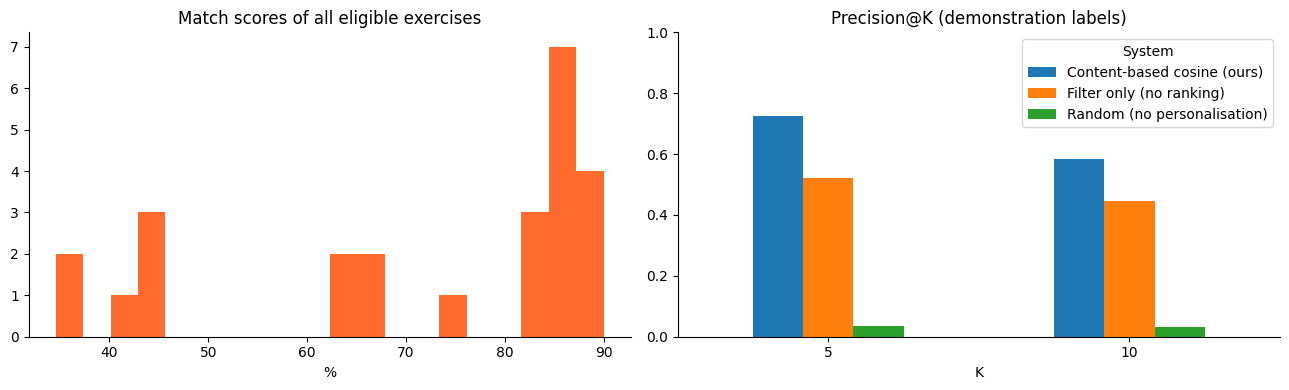

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(result.ranked["match_percent"], bins=20, color="#FF6B2C")
axes[0].set_title("Match scores of all eligible exercises"); axes[0].set_xlabel("%")
pivot = grid.pivot(index="K", columns="System", values="Precision@K")
pivot.plot.bar(ax=axes[1], rot=0); axes[1].set_ylim(0, 1)
axes[1].set_title("Precision@K (demonstration labels)")
plt.tight_layout(); plt.show()

## 17. Conclusion

* The recommender represents users and exercises in the **same weighted feature space** and ranks
  eligible exercises by **cosine similarity** — a transparent content-based approach that needs no
  user history (no cold-start problem for new users).
* A hard filter with a relaxation cascade guarantees safe, non-empty results.
* Every score decomposes into per-feature contributions, so each recommendation is explainable.
* The workout generator turns the ranking into a time-fitted, diverse session.
* Evaluation here is a **demonstration** with synthetic labels; real validation would need user studies.

> ⚠️ This project is developed for educational purposes. Workout recommendations are general informational suggestions and are not medical advice or a substitute for a qualified fitness professional.